In [93]:
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.append("./srcs")
import utils

# Ground-truth centers
with open("./release_assets/metadata/new_hsp60/centers3.pkl", "rb") as f:
    hsp60_centers = pickle.load(f)

# DeePiCt result folders for the two runs
runs = {
    "deepict_depth3": Path("/virtual_data/train_data/training/deepict/leave_one_out_hsp60/results"),
    "deepict_depth2": Path("/virtual_data/train_data/training/deepict/leave_one_out_hsp60_depth2/results"),
}

# Match radius in voxels (same style as DeepETPicker assess notebook)
MATCH_THRESHOLD = 20


def score_one_run(run_name, run_dir, centers_dict, threshold=20):
    rows = []
    micro_tp = micro_fp = micro_fn = 0

    for tomo_id in sorted(centers_dict.keys()):
        pred_files = list(run_dir.glob(f"*_{tomo_id}_pred_coords.csv"))
        if not pred_files:
            rows.append({
                "run": run_name,
                "tomo": tomo_id,
                "gt": len(centers_dict[tomo_id]),
                "pred": 0,
                "tp": 0,
                "fp": 0,
                "fn": len(centers_dict[tomo_id]),
                "precision": 0.0,
                "recall": 0.0,
                "f1": 0.0,
                "pred_file": None,
            })
            micro_fn += len(centers_dict[tomo_id])
            continue

        pred_file = pred_files[0]
        pred_df = pd.read_csv(pred_file, header=None)

        # DeePiCt motl coords are in columns [9, 8, 7] -> (x, y, z)
        pred_center = pred_df[[9, 8, 7]].values.astype(float)
        labels = np.array(centers_dict[tomo_id], dtype=float)

        _, match_dists, _ = utils.match_and_find_closest(pred_center, labels)
        tp = int(np.sum(match_dists < threshold))

        gt_n = len(labels)
        pred_n = len(pred_center)
        fp = pred_n - tp
        fn = gt_n - tp

        precision = tp / pred_n if pred_n else 0.0
        recall = tp / gt_n if gt_n else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

        rows.append({
            "run": run_name,
            "tomo": tomo_id,
            "gt": gt_n,
            "pred": pred_n,
            "tp": tp,
            "fp": fp,
            "fn": fn,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "pred_file": str(pred_file),
        })

        micro_tp += tp
        micro_fp += fp
        micro_fn += fn

    p = micro_tp / (micro_tp + micro_fp) if (micro_tp + micro_fp) else 0.0
    r = micro_tp / (micro_tp + micro_fn) if (micro_tp + micro_fn) else 0.0
    micro_f1 = (2 * p * r / (p + r)) if (p + r) > 0 else 0.0

    micro_row = {
        "run": run_name,
        "tomo": "MICRO",
        "gt": int(micro_tp + micro_fn),
        "pred": int(micro_tp + micro_fp),
        "tp": int(micro_tp),
        "fp": int(micro_fp),
        "fn": int(micro_fn),
        "precision": p,
        "recall": r,
        "f1": micro_f1,
        "pred_file": None,
    }

    return pd.DataFrame(rows), pd.DataFrame([micro_row])


all_detail = []
all_micro = []

for run_name, run_dir in runs.items():
    detail_df, micro_df = score_one_run(run_name, run_dir, hsp60_centers, MATCH_THRESHOLD)
    all_detail.append(detail_df)
    all_micro.append(micro_df)

    print(f"\n=== {run_name} (threshold={MATCH_THRESHOLD}) ===")
    print(detail_df[["tomo", "gt", "pred", "tp", "precision", "recall", "f1"]].to_string(index=False))
    print(micro_df[["tomo", "tp", "fp", "fn", "precision", "recall", "f1"]].to_string(index=False))

results_detail = pd.concat(all_detail, ignore_index=True)
results_micro = pd.concat(all_micro, ignore_index=True)

print("\nSummary (micro-F1):")
print(results_micro[["run", "precision", "recall", "f1"]].to_string(index=False))

# Save outputs for later use
out_dir = Path("./deepict")
out_dir.mkdir(parents=True, exist_ok=True)
results_detail.to_csv(out_dir / "deepict_f1_detail.csv", index=False)
results_micro.to_csv(out_dir / "deepict_f1_micro.csv", index=False)

results_micro


=== deepict_depth3 (threshold=20) ===
    tomo  gt  pred  tp  precision   recall       f1
24092001 321   243  14   0.057613 0.043614 0.049645
24092002 272   808  15   0.018564 0.055147 0.027778
24092018 247   179   2   0.011173 0.008097 0.009390
24092024 311   257   2   0.007782 0.006431 0.007042
24092028  89  1171   1   0.000854 0.011236 0.001587
24092031 302   619   2   0.003231 0.006623 0.004343
 tomo  tp   fp   fn  precision   recall       f1
MICRO  36 3241 1506   0.010986 0.023346 0.014941

=== deepict_depth2 (threshold=20) ===
    tomo  gt  pred  tp  precision   recall       f1
24092001 321   280  56   0.200000 0.174455 0.186356
24092002 272   320  19   0.059375 0.069853 0.064189
24092018 247  1102  54   0.049002 0.218623 0.080059
24092024 311   297  40   0.134680 0.128617 0.131579
24092028  89    94  10   0.106383 0.112360 0.109290
24092031 302   245  47   0.191837 0.155629 0.171846
 tomo  tp   fp   fn  precision   recall       f1
MICRO 226 2112 1316   0.096664 0.146563 0.11649

,run,tomo,gt,pred,tp,fp,fn,precision,recall,f1,pred_file
0,deepict_depth3,MICRO,1542,3277,36,3241,1506,0.010986,0.023346,0.014941,None
1,deepict_depth2,MICRO,1542,2338,226,2112,1316,0.096664,0.146563,0.116495,None


In [50]:
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.append("./srcs")
import utils

# Ground-truth ribosome centers (14 tomograms)
with open("/virtual_data/train_data/training/cr/temp/ribo_centers_new.pkl", "rb") as f:
    ribo_centers = pickle.load(f)

# DeePiCt ribosome outputs generated by deepict/ribosome.ipynb
base_out = Path("/virtual_data/train_data/training/deepict/two_fold_ribosome_depth2")
fold_outputs = [
    base_out / "fold1_train_fold2_test_out",
    base_out / "fold2_train_fold1_test_out",
]

pred_map = {}
for out_dir in fold_outputs:
    for p in out_dir.glob("predictions/*/*/ribosome/motl_*.csv"):
        tomo_id = p.parents[1].name
        pred_map[tomo_id] = p

expected = sorted(ribo_centers.keys())
found = sorted(pred_map.keys())
print("Predictions found for:", found)
missing = sorted(set(expected) - set(found))
if missing:
    raise ValueError(f"Missing predictions for tomograms: {missing}")

MATCH_THRESHOLD = 20
rows = []
micro_tp = micro_fp = micro_fn = 0

for tomo_id in expected:
    pred_file = pred_map[tomo_id]
    pred_df = pd.read_csv(pred_file, header=None)

    # DeePiCt motl format stores coordinates in columns [9, 8, 7] => (x, y, z)
    pred_center = pred_df[[9, 8, 7]].values.astype(float)
    labels = np.array(ribo_centers[tomo_id], dtype=float)

    _, match_dists, _ = utils.match_and_find_closest(pred_center, labels)
    tp = int(np.sum(match_dists < MATCH_THRESHOLD))

    gt_n = len(labels)
    pred_n = len(pred_center)
    fp = pred_n - tp
    fn = gt_n - tp

    precision = tp / pred_n if pred_n else 0.0
    recall = tp / gt_n if gt_n else 0.0
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0

    rows.append({
        "run": "deepict_ribosome_depth2_2fold",
        "tomo": tomo_id,
        "gt": gt_n,
        "pred": pred_n,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "pred_file": str(pred_file),
    })

    micro_tp += tp
    micro_fp += fp
    micro_fn += fn

p = micro_tp / (micro_tp + micro_fp) if (micro_tp + micro_fp) else 0.0
r = micro_tp / (micro_tp + micro_fn) if (micro_tp + micro_fn) else 0.0
micro_f1 = (2 * p * r / (p + r)) if (p + r) > 0 else 0.0

results_detail_ribo = pd.DataFrame(rows)
results_micro_ribo = pd.DataFrame([
    {
        "run": "deepict_ribosome_depth2_2fold",
        "tomo": "MICRO",
        "gt": int(micro_tp + micro_fn),
        "pred": int(micro_tp + micro_fp),
        "tp": int(micro_tp),
        "fp": int(micro_fp),
        "fn": int(micro_fn),
        "precision": p,
        "recall": r,
        "f1": micro_f1,
        "pred_file": None,
    }
])

print("\nRibosome per-tomogram results:")
print(results_detail_ribo[["tomo", "gt", "pred", "tp", "precision", "recall", "f1"]].to_string(index=False))
print("\nRibosome micro result:")
print(results_micro_ribo[["run", "precision", "recall", "f1"]].to_string(index=False))

out_dir = Path("./deepict")
out_dir.mkdir(parents=True, exist_ok=True)
results_detail_ribo.to_csv(out_dir / "deepict_ribo_f1_detail.csv", index=False)
results_micro_ribo.to_csv(out_dir / "deepict_ribo_f1_micro.csv", index=False)

results_micro_ribo

Predictions found for: ['24092002', '24092009', '24092013', '24092014', '24092016', '24092017', '24092020', '24092023', '24092024', '24092025', '24092026', '24092029', '24092030', '24092031']

Ribosome per-tomogram results:
    tomo   gt  pred  tp  precision   recall       f1
24092002  388   497  59   0.118712 0.152062 0.133333
24092009  759   625 206   0.329600 0.271410 0.297688
24092013 1453  1403 205   0.146115 0.141087 0.143557
24092014 1049   646 158   0.244582 0.150620 0.186431
24092016 1298   654 165   0.252294 0.127119 0.169057
24092017 1074   658 145   0.220365 0.135009 0.167436
24092020  479   540 103   0.190741 0.215031 0.202159
24092023  791   627 300   0.478469 0.379267 0.423131
24092024  348   531  78   0.146893 0.224138 0.177474
24092025  294   839  73   0.087008 0.248299 0.128861
24092026  957   609 226   0.371100 0.236155 0.288633
24092029  598   600 247   0.411667 0.413043 0.412354
24092030  267   368  54   0.146739 0.202247 0.170079
24092031  311   550  80   0.145455

,run,tomo,gt,pred,tp,fp,fn,precision,recall,f1,pred_file
0,deepict_ribosome_depth2_2fold,MICRO,10066,9147,2099,7048,7967,0.229474,0.208524,0.218498,None


In [55]:
import mrcfile


def readTomogram(filename):
    with mrcfile.open(filename, permissive=True) as m:
        return m.data

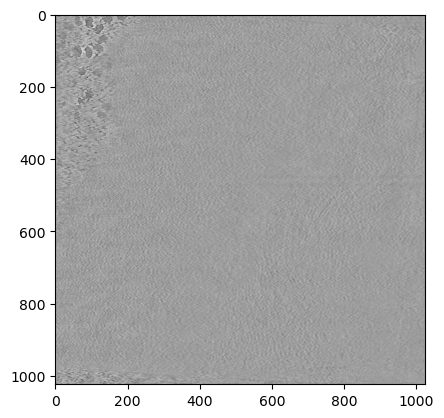

In [88]:
import matplotlib.pyplot as plt
import pandas as pd 
df = pd.read_csv("./release_assets/external/DeePiCt/3d_cnn/metadata_dxd20240920_ribo.csv")
t = df.loc[0, "tomo"]
l = df.loc[0, "ribosome_mask"]
t = readTomogram(t)
l = readTomogram(l)
plt.imshow(t[100], cmap="gray")

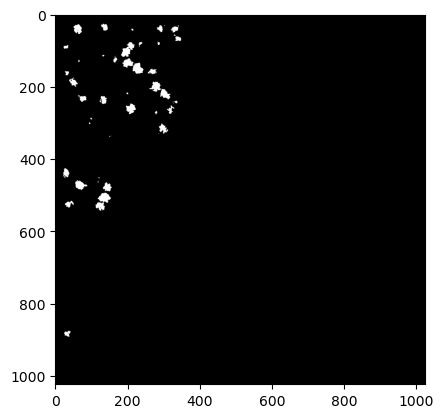

In [89]:
plt.imshow(l[150], cmap="gray")

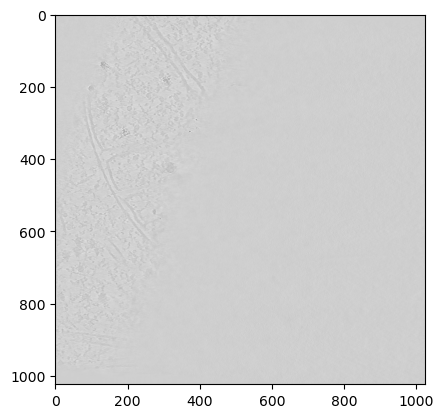

In [90]:
df = pd.read_csv("./release_assets/external/DeePiCt/3d_cnn/metadata_hsp60_611.csv")
t = df.loc[0, "tomo"]
l = df.loc[0, "hsp60_mask"]
t = readTomogram(t)
l = readTomogram(l)
plt.imshow(t[150], cmap="gray")

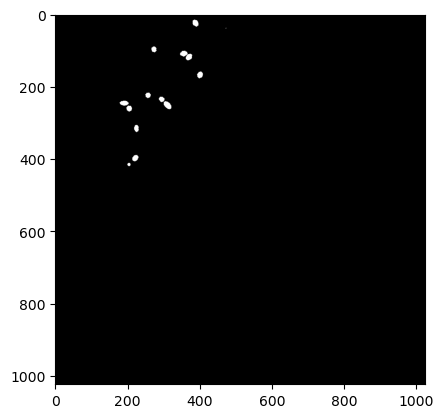

In [92]:
plt.imshow(l[150], cmap="gray")

In [80]:
import os
import numpy as np
for i in os.listdir("/virtual_data/test_data/dxd20240920_hsp60_0417_groundtruth/"):
    print(i)
    if i.endswith(".mrc"):
        t = readTomogram(f"/virtual_data/test_data/dxd20240920_hsp60_0417_groundtruth/{i}")
        q = np.array(t)
        q[q>0] = 1 
        print(np.max(q))
        with mrcfile.new(f"/virtual_data/test_data/dxd20240920_hsp60_0417_groundtruth/binary/{i.replace('.mrc', '_binary.mrc')}", overwrite=True) as m:
            m.set_data(q.astype(np.float32))

24092031.mrc
1
24092028.mrc
1
24092024.mrc
1
24092018.mrc
1
24092002.mrc
1
24092001.mrc
1
24092031_hsp60.pkl
24092028_hsp60.pkl
24092024_hsp60.pkl
24092018_hsp60.pkl
24092002_hsp60.pkl
24092001_hsp60.pkl
binary


In [75]:
df = df.set_index("tomo_name")
for i in df.index:
    df.loc[i, "hsp60_mask"] = f"/virtual_data/test_data/dxd20240920_hsp60_0417_groundtruth/binary/{i}_binary.mrc"

In [76]:
df.to_csv("./release_assets/external/DeePiCt/3d_cnn/metadata_hsp60_611.csv")

In [94]:
# Validate and score latest depth-2 hsp60 rerun outputs
from pathlib import Path
import pandas as pd

run_root = Path("/virtual_data/train_data/training/deepict/leave_one_out_hsp60_depth2")
results_dir = run_root / "results"
results_csv = run_root / "leave_one_out_results_depth2.csv"

if not results_csv.exists():
    raise FileNotFoundError(f"Missing run summary: {results_csv}")

res_df = pd.read_csv(results_csv)
print("Latest run status:")
print(res_df[["fold_name", "holdout_name", "exit_code", "duration_sec"]].to_string(index=False))

failed = int((res_df["exit_code"] != 0).sum())
if failed != 0:
    raise AssertionError(f"Still has failed folds: {failed}/6")

missing_pred = []
empty_pred = []
for _, row in res_df.iterrows():
    pred_path = row.get("prediction_coords")
    fold_name = row["fold_name"]
    if pd.isna(pred_path) or not str(pred_path).strip():
        missing_pred.append(fold_name)
        continue

    pred_file = Path(str(pred_path))
    if not pred_file.exists():
        missing_pred.append(fold_name)
        continue

    pred_df = pd.read_csv(pred_file, header=None)
    if pred_df.empty:
        empty_pred.append(fold_name)

if missing_pred:
    raise AssertionError(f"Missing prediction CSV for folds: {missing_pred}")
if empty_pred:
    raise AssertionError(f"Empty prediction CSV for folds: {empty_pred}")

detail_new, micro_new = score_one_run(
    "deepict_depth2_latest",
    results_dir,
    hsp60_centers,
    MATCH_THRESHOLD,
  )

print("\nRecomputed depth-2 per-tomo metrics:")
print(detail_new[["tomo", "gt", "pred", "tp", "precision", "recall", "f1"]].to_string(index=False))
print("\nRecomputed depth-2 micro metrics:")
print(micro_new[["run", "precision", "recall", "f1"]].to_string(index=False))

out_dir = Path("./deepict")
detail_new.to_csv(out_dir / "deepict_depth2_latest_f1_detail.csv", index=False)
micro_new.to_csv(out_dir / "deepict_depth2_latest_f1_micro.csv", index=False)
print("\nSaved:")
print(out_dir / "deepict_depth2_latest_f1_detail.csv")
print(out_dir / "deepict_depth2_latest_f1_micro.csv")

Latest run status:
             fold_name  holdout_name  exit_code  duration_sec
hsp60d2_loo_0_24092001      24092001          0        755.21
hsp60d2_loo_1_24092002      24092002          0        769.93
hsp60d2_loo_2_24092018      24092018          0        770.83
hsp60d2_loo_3_24092024      24092024          0        742.41
hsp60d2_loo_4_24092028      24092028          0        891.27
hsp60d2_loo_5_24092031      24092031          0        775.24

Recomputed depth-2 per-tomo metrics:
    tomo  gt  pred  tp  precision   recall       f1
24092001 321   280  56   0.200000 0.174455 0.186356
24092002 272   320  19   0.059375 0.069853 0.064189
24092018 247  1102  54   0.049002 0.218623 0.080059
24092024 311   297  40   0.134680 0.128617 0.131579
24092028  89    94  10   0.106383 0.112360 0.109290
24092031 302   245  47   0.191837 0.155629 0.171846

Recomputed depth-2 micro metrics:
                  run  precision   recall       f1
deepict_depth2_latest   0.096664 0.146563 0.116495

Saved:


In [95]:
# Update assessment summary with tuned post-processing results from parameter_tuning.ipynb
from pathlib import Path
import pandas as pd

out_dir = Path("./deepict")
hsp60_grid_file = out_dir / "hsp60_pp_grid.csv"
ribo_grid_file = out_dir / "ribo_pp_grid.csv"

if not hsp60_grid_file.exists() or not ribo_grid_file.exists():
    raise FileNotFoundError("Run deepict/parameter_tuning.ipynb first to generate hsp60_pp_grid.csv and ribo_pp_grid.csv")

hsp60_grid = pd.read_csv(hsp60_grid_file).sort_values("f1", ascending=False).reset_index(drop=True)
ribo_grid = pd.read_csv(ribo_grid_file).sort_values("f1", ascending=False).reset_index(drop=True)

best_hsp60 = hsp60_grid.iloc[0]
best_ribo = ribo_grid.iloc[0]

summary = pd.DataFrame([
    {
        "dataset": "hsp60",
        "source": "DeePiCt depth2 tuned postprocess",
        "threshold": float(best_hsp60["threshold"]),
        "min_cluster": int(best_hsp60["min_cluster"]),
        "max_cluster": int(best_hsp60["max_cluster"]),
        "precision": float(best_hsp60["precision"]),
        "recall": float(best_hsp60["recall"]),
        "f1": float(best_hsp60["f1"]),
    },
    {
        "dataset": "ribosome",
        "source": "DeePiCt depth2 tuned postprocess",
        "threshold": float(best_ribo["threshold"]),
        "min_cluster": int(best_ribo["min_cluster"]),
        "max_cluster": int(best_ribo["max_cluster"]),
        "precision": float(best_ribo["precision"]),
        "recall": float(best_ribo["recall"]),
        "f1": float(best_ribo["f1"]),
    },
])

print("Tuned DeePiCt post-processing summary:")
print(summary.to_string(index=False))

summary.to_csv(out_dir / "deepict_tuned_postprocess_summary.csv", index=False)
summary[summary["dataset"] == "hsp60"][["source", "precision", "recall", "f1"]].to_csv(out_dir / "deepict_hsp60_tuned_micro.csv", index=False)
summary[summary["dataset"] == "ribosome"][["source", "precision", "recall", "f1"]].to_csv(out_dir / "deepict_ribo_tuned_micro.csv", index=False)

print("\nSaved:")
print(out_dir / "deepict_tuned_postprocess_summary.csv")
print(out_dir / "deepict_hsp60_tuned_micro.csv")
print(out_dir / "deepict_ribo_tuned_micro.csv")

Tuned DeePiCt post-processing summary:
 dataset                           source  threshold  min_cluster  max_cluster  precision   recall       f1
   hsp60 DeePiCt depth2 tuned postprocess        0.7           20         2000   0.238620 0.322957 0.274456
ribosome DeePiCt depth2 tuned postprocess        0.6          200        10000   0.314491 0.296245 0.305095

Saved:
./deepict/deepict_tuned_postprocess_summary.csv
./deepict/deepict_hsp60_tuned_micro.csv
./deepict/deepict_ribo_tuned_micro.csv


In [97]:
"""
Write best-params predictions to results directories.
- hsp60 : overwrites hsp60d2_loo_*_pred_coords.csv in leave_one_out_hsp60_depth2/results/
- ribo  : overwrites motl_*.csv in two_fold_ribosome_depth2/...predictions/.../ribosome/
No retraining — only post-processing on stored probability_map.mrc files.
"""
import sys, pickle
from pathlib import Path

import numpy as np
import pandas as pd
import mrcfile
from scipy.ndimage import label as scipy_label
from skimage.measure import regionprops_table

sys.path.append("./srcs")
import utils   # noqa: F811

# ── Load best params from tuning grids ──────────────────────────────────────
out_dir = Path("./deepict")
hsp60_grid = pd.read_csv(out_dir / "hsp60_pp_grid.csv").sort_values("f1", ascending=False)
ribo_grid  = pd.read_csv(out_dir / "ribo_pp_grid.csv").sort_values("f1", ascending=False)

best_hsp60 = hsp60_grid.iloc[0]
best_ribo  = ribo_grid.iloc[0]

print(f"Best hsp60 params → thr={best_hsp60.threshold}  min={int(best_hsp60.min_cluster)}  max={int(best_hsp60.max_cluster)}  F1={best_hsp60.f1:.4f}")
print(f"Best ribo  params → thr={best_ribo.threshold}   min={int(best_ribo.min_cluster)}  max={int(best_ribo.max_cluster)}  F1={best_ribo.f1:.4f}")


# ── Post-processing helpers ─────────────────────────────────────────────────
def postprocess_probmap(prob_vol, threshold, min_cs, max_cs):
    """Return (N,3) centroids (z,y,x) filtered by cluster size."""
    binary = (prob_vol >= threshold).astype(np.uint8)
    struct = np.ones((3, 3, 3), dtype=np.uint8)
    labeled, num = scipy_label(binary, structure=struct)
    if num == 0:
        return np.empty((0, 3), dtype=np.float32)
    props = regionprops_table(labeled, properties=("area", "centroid"))
    areas = np.asarray(props["area"], dtype=np.int32)
    cts   = np.column_stack([props["centroid-0"], props["centroid-1"], props["centroid-2"]]).astype(np.float32)
    mask  = (areas > min_cs) & (areas <= max_cs)
    return cts[mask]


def centroids_to_motl(centroids):
    """
    Convert (N,3) (z,y,x) array to 20-column DeePiCt motl DataFrame.
    Layout: score, x, y, id, 0,0,0, x, y, z, 0*9, 1
    score_one_run reads cols [9,8,7] = (z, y, x).
    """
    n = len(centroids)
    if n == 0:
        return pd.DataFrame(columns=range(20))
    z = centroids[:, 0]
    y = centroids[:, 1]
    x = centroids[:, 2]
    data = np.zeros((n, 20), dtype=np.float32)
    data[:, 0]  = 1
    data[:, 1]  = x
    data[:, 2]  = y
    data[:, 3]  = np.arange(1, n + 1)
    data[:, 7]  = x
    data[:, 8]  = y
    data[:, 9]  = z
    data[:, 19] = 1
    return pd.DataFrame(data.astype(int))


def score_cts(cts, gt_arr, match_thr=20):
    n_pred = len(cts)
    n_gt   = len(gt_arr)
    if n_pred > 0 and n_gt > 0:
        _, dists, _ = utils.match_and_find_closest(cts, gt_arr)
        tp = int(np.sum(dists < match_thr))
    else:
        tp = 0
    fp = n_pred - tp
    fn = n_gt  - tp
    prec = tp / n_pred if n_pred else 0.0
    rec  = tp / n_gt   if n_gt   else 0.0
    f1   = 2*prec*rec/(prec+rec) if (prec+rec) > 0 else 0.0
    return dict(n_gt=n_gt, n_pred=n_pred, tp=tp, fp=fp, fn=fn, precision=prec, recall=rec, f1=f1)


# ── hsp60 : overwrite pred_coords.csv files ─────────────────────────────────
hsp60_base    = Path("/virtual_data/train_data/training/deepict/leave_one_out_hsp60_depth2")
hsp60_res_dir = hsp60_base / "results"
hsp60_res_dir.mkdir(parents=True, exist_ok=True)

hsp60_prob_maps = {}
for fold_dir in sorted(hsp60_base.glob("hsp60d2_loo_*_out")):
    for mrc in fold_dir.glob("predictions/*/*/hsp60/probability_map.mrc"):
        tomo_id = mrc.parents[1].name
        hsp60_prob_maps[tomo_id] = mrc

hsp60_rows = []
for tomo_id, prob_file in sorted(hsp60_prob_maps.items()):
    with mrcfile.open(str(prob_file), permissive=True) as m:
        vol = m.data.astype(np.float32)
    cts = postprocess_probmap(vol, float(best_hsp60.threshold),
                              int(best_hsp60.min_cluster), int(best_hsp60.max_cluster))
    fold_name = prob_file.parents[4].name.replace("_out", "")
    dst = hsp60_res_dir / f"{fold_name}_pred_coords.csv"
    centroids_to_motl(cts).to_csv(dst, index=False, header=False)

    gt_arr = np.array(hsp60_centers[tomo_id], dtype=np.float32) if tomo_id in hsp60_centers else np.empty((0, 3))
    sc = score_cts(cts, gt_arr)
    hsp60_rows.append(dict(tomo=tomo_id, **sc))
    print(f"  hsp60 {tomo_id}: pred={sc['n_pred']}  tp={sc['tp']}  F1={sc['f1']:.4f}  → {dst.name}")

hsp60_df = pd.DataFrame(hsp60_rows)
mtp = hsp60_df.tp.sum(); mfp = hsp60_df.fp.sum(); mfn = hsp60_df.fn.sum()
p_ = mtp/(mtp+mfp) if (mtp+mfp) else 0.0
r_ = mtp/(mtp+mfn) if (mtp+mfn) else 0.0
hsp60_micro_f1 = 2*p_*r_/(p_+r_) if (p_+r_) > 0 else 0.0
print(f"\nhsp60 micro-F1 (tuned): {hsp60_micro_f1:.4f}  precision={p_:.4f}  recall={r_:.4f}")


# ── Ribosome : overwrite motl_*.csv files inside prediction tree ─────────────
ribo_base = Path("/virtual_data/train_data/training/deepict/two_fold_ribosome_depth2")

ribo_prob_maps = {}
for fold_out in sorted(ribo_base.glob("*_out")):
    for mrc in fold_out.glob("predictions/*/*/ribosome/probability_map.mrc"):
        tomo_id = mrc.parents[1].name
        motl_files = list(mrc.parent.glob("motl_*.csv"))
        ribo_prob_maps[tomo_id] = (mrc, motl_files[0] if motl_files else None)

ribo_rows = []
for tomo_id, (prob_file, orig_motl) in sorted(ribo_prob_maps.items()):
    with mrcfile.open(str(prob_file), permissive=True) as m:
        vol = m.data.astype(np.float32)
    cts = postprocess_probmap(vol, float(best_ribo.threshold),
                              int(best_ribo.min_cluster), int(best_ribo.max_cluster))
    motl_df = centroids_to_motl(cts)
    if orig_motl is not None:
        motl_df.to_csv(orig_motl, index=False, header=False)
        dst_label = orig_motl.name
    else:
        dst = prob_file.parent / f"motl_{len(cts)}.csv"
        motl_df.to_csv(dst, index=False, header=False)
        dst_label = dst.name

    gt_arr = np.array(ribo_centers[tomo_id], dtype=np.float32) if tomo_id in ribo_centers else np.empty((0, 3))
    sc = score_cts(cts, gt_arr)
    ribo_rows.append(dict(tomo=tomo_id, **sc))
    print(f"  ribo  {tomo_id}: pred={sc['n_pred']}  tp={sc['tp']}  F1={sc['f1']:.4f}  → {dst_label}")

ribo_df = pd.DataFrame(ribo_rows)
r_mtp = ribo_df.tp.sum(); r_mfp = ribo_df.fp.sum(); r_mfn = ribo_df.fn.sum()
rp_ = r_mtp/(r_mtp+r_mfp) if (r_mtp+r_mfp) else 0.0
rr_ = r_mtp/(r_mtp+r_mfn) if (r_mtp+r_mfn) else 0.0
ribo_micro_f1 = 2*rp_*rr_/(rp_+rr_) if (rp_+rr_) > 0 else 0.0
print(f"\nribosome micro-F1 (tuned): {ribo_micro_f1:.4f}  precision={rp_:.4f}  recall={rr_:.4f}")

print("\n" + "="*60)
print("FINAL — tuned post-processing results written")
print("="*60)
print(f"  hsp60     micro-F1 = {hsp60_micro_f1:.4f}  (thr={best_hsp60.threshold}, min={int(best_hsp60.min_cluster)}, max={int(best_hsp60.max_cluster)})")
print(f"  ribosome  micro-F1 = {ribo_micro_f1:.4f}  (thr={best_ribo.threshold},  min={int(best_ribo.min_cluster)}, max={int(best_ribo.max_cluster)})")


Best hsp60 params → thr=0.7  min=20  max=2000  F1=0.2745
Best ribo  params → thr=0.6   min=200  max=10000  F1=0.3051
  hsp60 24092001: pred=289  tp=116  F1=0.3803  → hsp60d2_loo_0_24092001_pred_coords.csv
  hsp60 24092002: pred=345  tp=68  F1=0.2204  → hsp60d2_loo_1_24092002_pred_coords.csv
  hsp60 24092018: pred=852  tp=94  F1=0.1711  → hsp60d2_loo_2_24092018_pred_coords.csv
  hsp60 24092024: pred=323  tp=110  F1=0.3470  → hsp60d2_loo_3_24092024_pred_coords.csv
  hsp60 24092028: pred=73  tp=13  F1=0.1605  → hsp60d2_loo_4_24092028_pred_coords.csv
  hsp60 24092031: pred=205  tp=97  F1=0.3826  → hsp60d2_loo_5_24092031_pred_coords.csv

hsp60 micro-F1 (tuned): 0.2745  precision=0.2386  recall=0.3230
  ribo  24092002: pred=434  tp=73  F1=0.1776  → motl_497.csv
  ribo  24092009: pred=666  tp=296  F1=0.4154  → motl_625.csv
  ribo  24092013: pred=1535  tp=270  F1=0.1807  → motl_1403.csv
  ribo  24092014: pred=732  tp=251  F1=0.2819  → motl_646.csv
  ribo  24092016: pred=762  tp=264  F1=0.2563 